Filename: crazing_1.jpg
Image size: 200 x 200
Objects: [{'class_name': 'crazing', 'xmin': 2, 'ymin': 2, 'xmax': 193, 'ymax': 194}]


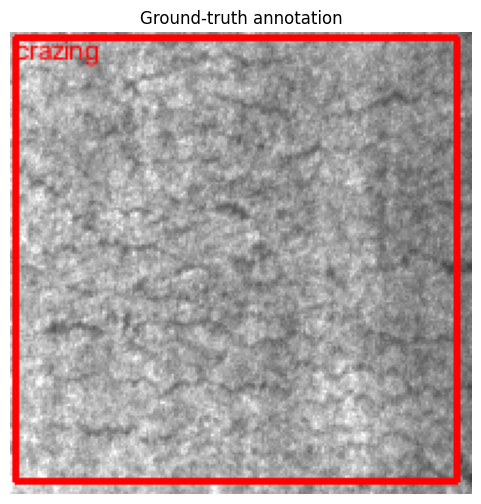

In [1]:

from pathlib import Path
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw/NEU-DET")

ANNOTATION_DIR = DATA_DIR / "train" / "annotations"
IMAGE_DIR = DATA_DIR / "train" / "images"

def parse_annotation(xml_path):
    root = ET.parse(xml_path).getroot()

    filename = root.findtext("filename")
    size = root.find("size")

    width = int(size.findtext("width"))
    height = int(size.findtext("height"))

    objects = []

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        objects.append({
            "class_name": obj.findtext("name"),
            "xmin": int(box.findtext("xmin")),
            "ymin": int(box.findtext("ymin")),
            "xmax": int(box.findtext("xmax")),
            "ymax": int(box.findtext("ymax")),
        })

    return {
        "filename": filename,
        "width": width,
        "height": height,
        "objects": objects,
    }


# Inspect one annotation.
xml_path = ANNOTATION_DIR / "crazing_1.xml"
annotation = parse_annotation(xml_path)

print("Filename:", annotation["filename"])
print(
    "Image size:",
    annotation["width"],
    "x",
    annotation["height"],
)
print("Objects:", annotation["objects"])

# Find the image in the class subfolders.
matches = list(
    IMAGE_DIR.rglob(annotation["filename"])
)

if not matches:
    raise FileNotFoundError(
        f"Image not found: {annotation['filename']}"
    )

image = cv2.imread(str(matches[0]))

if image is None:
    raise ValueError("Could not read image.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for obj in annotation["objects"]:
    cv2.rectangle(
        image,
        (obj["xmin"], obj["ymin"]),
        (obj["xmax"], obj["ymax"]),
        (255, 0, 0),
        2,
    )

    cv2.putText(
        image,
        obj["class_name"],
        (obj["xmin"], max(12, obj["ymin"] - 4)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (255, 0, 0),
        1,
    )

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Ground-truth annotation")
plt.axis("off")
plt.show()
